# MNLI analysis and tests

This notebook is a separate workspace for the slide-deck analysis. It imports the existing pipeline and does not edit the project source files.

Run `run_data.py` first for prepared-subset results, and `run_experiments.py` first for model metrics.

In [21]:
import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from pipeline.data import audit_data, load_mnli, load_saved_folds
from pipeline.evaluation import evaluate_predictions

RESULTS_ROOT = PROJECT_ROOT / "results_markus"
DATA_DIR = RESULTS_ROOT / "data" / "mnli-n50000-seed0"
EXPERIMENT_DIR = RESULTS_ROOT / "experiments" / "mnli-n50000-seed0"
OUTPUT_DIR = PROJECT_ROOT / "results" / "analysis"
LABEL_NAMES = {0: "entailment", 1: "neutral", 2: "contradiction"}

def inspect_prepared_subset():
    if not (DATA_DIR / "manifest.json").exists():
        print("Prepared data is not available. Run `uv run python run_data.py` first.")
        return
    subset, folds = load_saved_folds(DATA_DIR)
    audit = audit_data(subset)
    print(f"Prepared subset size: {len(subset):,}")
    print("Labels:", {LABEL_NAMES.get(int(k), str(k)): v for k, v in audit["label_counts"].items()})
    for fold_id, fold in folds.items():
        print(f"Fold {fold_id}: {len(fold['training']):,} training, {len(fold['validation']):,} validation")

def inspect_experiment_metrics():
    if not EXPERIMENT_DIR.exists():
        print("Experiment results are not available. Run `uv run python run_experiments.py` first.")
        return
    rows = []
    for path in EXPERIMENT_DIR.glob("*/*/metrics.json"):
        metrics = json.loads(path.read_text(encoding="utf-8"))
        rows.append({"model": path.parent.parent.name, "fold": path.parent.name,
                     "accuracy": metrics["accuracy"], "macro_f1": metrics["macro_f1"]})
    if rows:
        table = pd.DataFrame(rows).sort_values(["model", "fold"])
        display(table)
        display(table.groupby("model")[["accuracy", "macro_f1"]].agg(["mean", "std"]).round(4))
    else:
        print("No metrics.json files found.")

def run_small_sanity_tests():
    assert set(LABEL_NAMES) == {0, 1, 2}
    print("Sanity tests passed.")

print(f"Project root: {PROJECT_ROOT}")
print(f"Analysis output: {OUTPUT_DIR}")

Project root: /Users/lindevansaane/Onedrive/Msc Artificial Intelligence /Natural Language Processing 1/Projects/NLP1-Natural_Language_Inference-Project
Analysis output: /Users/lindevansaane/Onedrive/Msc Artificial Intelligence /Natural Language Processing 1/Projects/NLP1-Natural_Language_Inference-Project/results/analysis


## 1. Official MNLI dataset

In [22]:
# # mnli = load_mnli()

# # for split_name, split in mnli.items():
# #     print(f"{split_name}: {len(split):,} examples")

# from datasets import load_dataset

# mnli = {
#     "train": load_dataset(
#         "nyu-mll/multi_nli",
#         split="train[:5000]"
#     )
# }

# print(f"Loaded {len(mnli['train']):,} examples")

# import os

# os.environ["HF_HUB_DISABLE_XET"] = "1"
# os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

# from datasets import Dataset, load_dataset

# stream = load_dataset(
#     "nyu-mll/multi_nli",
#     split="train",
#     streaming=True,
# )

# examples = list(stream.take(5000))
# mnli = {"train": Dataset.from_list(examples)}

# print(f"Loaded {len(mnli['train']):,} examples")

from datasets import load_dataset

mnli = load_dataset("nyu-mll/multi_nli")

for split_name, split in mnli.items():
    print(f"{split_name}: {len(split):,} examples")

train: 392,702 examples
validation_matched: 9,815 examples
validation_mismatched: 9,832 examples


In [23]:
for split_name, split in mnli.items():
    audit = audit_data(split)
    print(f"\n{split_name}")
    print("Label counts:", {
        LABEL_NAMES.get(int(label), str(label)): count
        for label, count in audit["label_counts"].items()
    })
    print("Genre counts:", audit["genre_counts"])
    print("Duplicate rows:", audit["duplicate_rows"])
    print("Conflicting pairs:", len(audit["conflicting_pairs"]))
    print("Word lengths:", audit["word_lengths"])


train
Label counts: {'neutral': 130900, 'entailment': 130899, 'contradiction': 130903}
Genre counts: {'government': 77350, 'telephone': 83348, 'fiction': 77348, 'travel': 77350, 'slate': 77306}
Duplicate rows: 22
Conflicting pairs: 83
Word lengths: {'premise': {'min': 1, 'mean': 19.81103228402198, 'median': 17.0, 'max': 382}, 'hypothesis': {'min': 1, 'mean': 9.972062785521846, 'median': 9.0, 'max': 69}}

validation_matched
Label counts: {'neutral': 3123, 'contradiction': 3213, 'entailment': 3479}
Genre counts: {'slate': 1955, 'government': 1945, 'telephone': 1966, 'travel': 1976, 'fiction': 1973}
Duplicate rows: 0
Conflicting pairs: 0
Word lengths: {'premise': {'min': 1, 'mean': 19.266123280692817, 'median': 16, 'max': 196}, 'hypothesis': {'min': 1, 'mean': 9.916352521650534, 'median': 9, 'max': 46}}

validation_mismatched
Label counts: {'contradiction': 3240, 'entailment': 3463, 'neutral': 3129}
Genre counts: {'letters': 1977, 'verbatim': 1946, 'facetoface': 1974, 'oup': 1961, 'ninee

## 2. Prepared subset and cross-validation folds

In [24]:
inspect_prepared_subset()

Prepared subset size: 50,001
Labels: {'entailment': 16667, 'contradiction': 16667, 'neutral': 16667}
Fold 0: 39,999 training, 10,002 validation
Fold 1: 39,999 training, 10,002 validation
Fold 2: 40,002 training, 9,999 validation
Fold 3: 40,002 training, 9,999 validation
Fold 4: 40,002 training, 9,999 validation


In [25]:
if (DATA_DIR / "manifest.json").exists():
    subset, folds = load_saved_folds(DATA_DIR)
    print("Subset size:", len(subset))
    for label, count in subset.to_pandas()["label"].value_counts().sort_index().items():
        print(f"{LABEL_NAMES[int(label)]}: {count:,} ({count / len(subset):.2%})")
else:
    print("Prepared data is not available. Run `uv run python run_data.py` first.")

Subset size: 50001
entailment: 16,667 (33.33%)
neutral: 16,667 (33.33%)
contradiction: 16,667 (33.33%)


## 3. Experiment metrics

In [26]:
inspect_experiment_metrics()

,model,fold,accuracy,macro_f1
24,logistic_bow,fold-0,0.493101,0.493101
23,logistic_bow,fold-1,0.498000,0.498184
20,logistic_bow,fold-2,0.512951,0.513144
22,logistic_bow,fold-3,0.500550,0.500928
21,logistic_bow,fold-4,0.501950,0.502604
29,logistic_indicator,fold-0,0.495801,0.495786
28,logistic_indicator,fold-1,0.497500,0.497718
25,logistic_indicator,fold-2,0.511151,0.511291
27,logistic_indicator,fold-3,0.502750,0.503132
26,logistic_indicator,fold-4,0.502150,0.502810


accuracy         macro_f1        
                       mean     std     mean     std
model                                               
logistic_bow         0.5013  0.0073   0.5016  0.0074
logistic_indicator   0.5019  0.0060   0.5021  0.0060
logistic_overlap     0.5921  0.0019   0.5912  0.0018
majority             0.3333  0.0000   0.1667  0.0000
mlp2_bow             0.5030  0.0075   0.5031  0.0075
mlp2_indicator       0.5002  0.0033   0.5002  0.0036
mlp2_overlap         0.5720  0.0013   0.5714  0.0014
mlp_bow              0.5124  0.0025   0.5125  0.0026
mlp_indicator        0.5148  0.0054   0.5148  0.0055
mlp_overlap          0.5788  0.0033   0.5782  0.0032

In [18]:
# Optional: inspect one saved predictions file and calculate a detailed report.
prediction_files = list(EXPERIMENT_DIR.glob("*/*/predictions.csv"))
if prediction_files:
    predictions = __import__("pandas").read_csv(prediction_files[0])
    print(prediction_files[0])
    display(predictions.head())
    display(predictions.groupby("genre").size().rename("examples"))
else:
    print("No prediction files found. Run `uv run python run_experiments.py` first.")

/Users/lindevansaane/Onedrive/Msc Artificial Intelligence /Natural Language Processing 1/Projects/NLP1-Natural_Language_Inference-Project/results_markus/experiments/mnli-n50000-seed0/majority/fold-2/predictions.csv


,pairID,genre,gold_label,prediction,p_entailment,p_neutral,p_contradiction
0,94381c,travel,2,0,0.333333,0.333333,0.333333
1,94381n,travel,1,0,0.333333,0.333333,0.333333
2,94381e,travel,0,0,0.333333,0.333333,0.333333
3,57570c,fiction,2,0,0.333333,0.333333,0.333333
4,57570n,fiction,1,0,0.333333,0.333333,0.333333


genre
fiction       2091
government    1956
slate         1833
telephone     2154
travel        1965
Name: examples, dtype: int64

In [27]:
run_small_sanity_tests()

# Example custom test: evaluate a small set of manually chosen predictions.
gold = [0, 1, 2, 0, 1, 2]
predictions = [0, 2, 2, 0, 1, 0]
evaluate_predictions(gold, predictions)

Sanity tests passed.


{'accuracy': 0.6666666666666666,
 'macro_f1': 0.6555555555555556,
 'confusion_matrix': array([[2, 0, 0],
        [0, 1, 1],
        [1, 0, 1]])}

## 5. Inspect the saved results

The cells below analyse the completed runs in `results_markus`: model scores, plots, predictions, errors, genres, confusion matrices, and neural-network training history.

In [28]:
scores = pd.read_csv(EXPERIMENT_DIR / "fold_scores.csv")
scores.head()

,model,accuracy,run,fold,macro_f1
0,majority,0.333333,0,0,0.166667
1,majority,0.333333,0,1,0.166667
2,majority,0.333333,0,2,0.166667
3,majority,0.333333,0,3,0.166667
4,majority,0.333333,0,4,0.166667


In [29]:
summary = (
    scores.groupby("model")[["accuracy", "macro_f1"]]
    .agg(["mean", "std"])
    .round(4)
    .sort_values(("accuracy", "mean"), ascending=False)
)
summary

accuracy         macro_f1        
                       mean     std     mean     std
model                                               
logistic_overlap     0.5921  0.0019   0.5912  0.0018
mlp_overlap          0.5788  0.0033   0.5782  0.0032
mlp2_overlap         0.5720  0.0013   0.5714  0.0014
mlp_indicator        0.5148  0.0054   0.5148  0.0055
mlp_bow              0.5124  0.0025   0.5125  0.0026
mlp2_bow             0.5030  0.0075   0.5031  0.0075
logistic_indicator   0.5019  0.0060   0.5021  0.0060
logistic_bow         0.5013  0.0073   0.5016  0.0074
mlp2_indicator       0.5002  0.0033   0.5002  0.0036
majority             0.3333  0.0000   0.1667  0.0000

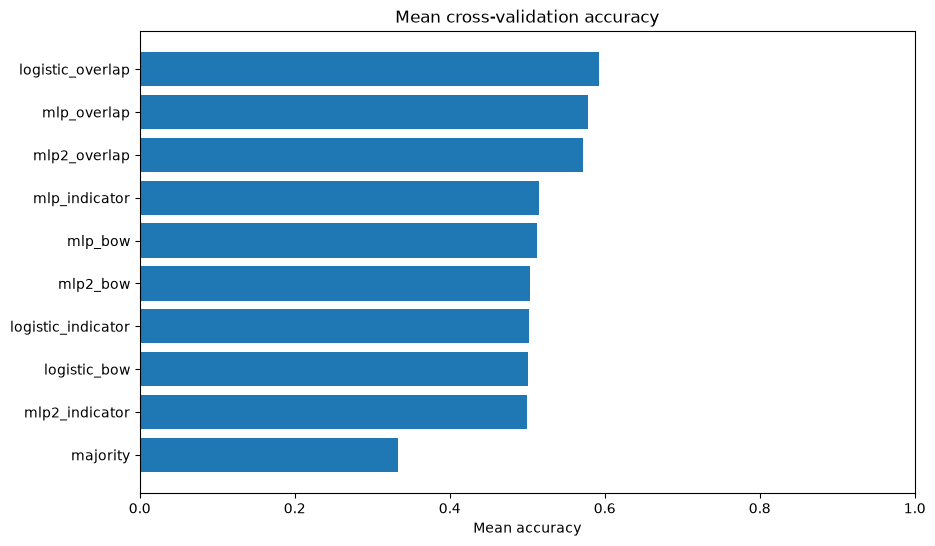

<Figure size 1200x600 with 0 Axes>

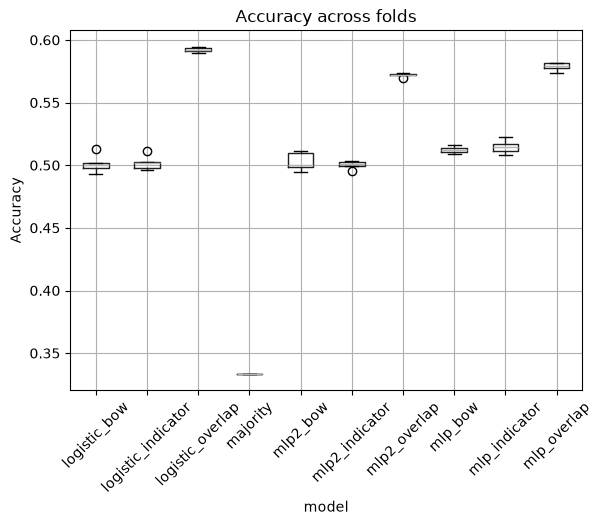

In [30]:
plot_data = (
    scores.groupby("model", as_index=False)["accuracy"]
    .mean()
    .sort_values("accuracy")
)

plt.figure(figsize=(10, 6))
plt.barh(plot_data["model"], plot_data["accuracy"])
plt.xlabel("Mean accuracy")
plt.title("Mean cross-validation accuracy")
plt.xlim(0, 1)
plt.show()

plt.figure(figsize=(12, 6))
scores.boxplot(column="accuracy", by="model", rot=45)
plt.title("Accuracy across folds")
plt.suptitle("")
plt.ylabel("Accuracy")
plt.show()

In [31]:
MODEL_TO_INSPECT = "logistic_overlap"
FOLD_TO_INSPECT = "fold-0"
prediction_path = EXPERIMENT_DIR / MODEL_TO_INSPECT / FOLD_TO_INSPECT / "predictions.csv"
predictions = pd.read_csv(prediction_path)
predictions.head()

,pairID,genre,gold_label,prediction,p_entailment,p_neutral,p_contradiction
0,8497n,travel,1,2,0.080862,0.209406,0.709732
1,8497c,travel,2,2,0.172890,0.346600,0.480510
2,8497e,travel,0,2,0.157061,0.105153,0.737786
3,9746e,government,0,0,0.985203,0.000688,0.014110
4,9746c,government,2,2,0.050067,0.060532,0.889402


In [13]:
errors = predictions[predictions["gold_label"] != predictions["prediction"]].copy()
errors["gold_name"] = errors["gold_label"].map(LABEL_NAMES)
errors["prediction_name"] = errors["prediction"].map(LABEL_NAMES)
errors[["pairID", "genre", "gold_name", "prediction_name",
         "p_entailment", "p_neutral", "p_contradiction"]].head(20)

,pairID,genre,gold_name,prediction_name,p_entailment,p_neutral,p_contradiction
0,8497n,travel,neutral,contradiction,0.080862,0.209406,0.709732
2,8497e,travel,entailment,contradiction,0.157061,0.105153,0.737786
10,31756e,fiction,entailment,neutral,0.302131,0.483067,0.214803
17,27780e,telephone,entailment,contradiction,0.257067,0.140620,0.602313
20,68631c,slate,contradiction,neutral,0.291608,0.354794,0.353598
21,68631n,slate,neutral,contradiction,0.141564,0.415139,0.443297
22,68631n,slate,neutral,entailment,0.561499,0.190037,0.248463
27,120599e,government,entailment,neutral,0.437715,0.469378,0.092907
31,106574c,travel,contradiction,neutral,0.060823,0.727304,0.211873
34,61635n,travel,neutral,contradiction,0.393202,0.146754,0.460043


In [32]:
predictions["correct"] = predictions["gold_label"] == predictions["prediction"]
display(predictions.groupby("genre")["correct"].agg(["count", "mean"]).sort_values("mean"))

print(classification_report(
    predictions["gold_label"],
    predictions["prediction"],
    labels=list(LABEL_NAMES),
    target_names=list(LABEL_NAMES.values()),
    zero_division=0,
))

,count,mean
genre,,
slate,1824,0.568531
fiction,2121,0.569543
telephone,2151,0.592748
government,2034,0.606195
travel,1872,0.618056


               precision    recall  f1-score   support

   entailment       0.60      0.65      0.63      3334
      neutral       0.58      0.56      0.57      3334
contradiction       0.59      0.56      0.57      3334

     accuracy                           0.59     10002
    macro avg       0.59      0.59      0.59     10002
 weighted avg       0.59      0.59      0.59     10002



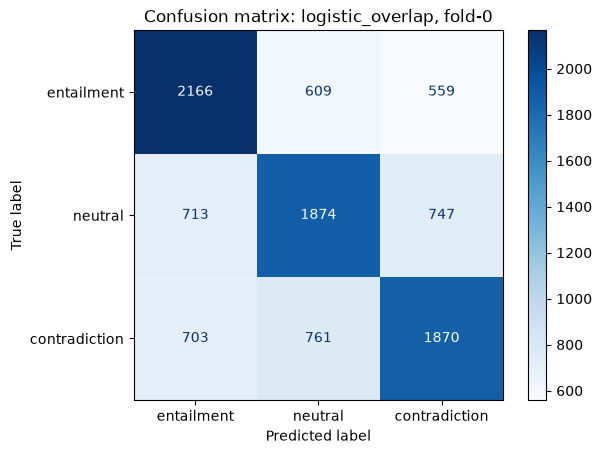

In [33]:
ConfusionMatrixDisplay.from_predictions(
    predictions["gold_label"],
    predictions["prediction"],
    labels=list(LABEL_NAMES),
    display_labels=list(LABEL_NAMES.values()),
    cmap="Blues",
)
plt.title(f"Confusion matrix: {MODEL_TO_INSPECT}, {FOLD_TO_INSPECT}")
plt.show()

In [34]:
prediction_tables = []
for path in EXPERIMENT_DIR.glob("*/fold-*/predictions.csv"):
    table = pd.read_csv(path)
    table["model"] = path.parent.parent.name
    table["fold"] = path.parent.name
    prediction_tables.append(table)

all_predictions = pd.concat(prediction_tables, ignore_index=True)
all_predictions["correct"] = all_predictions["gold_label"] == all_predictions["prediction"]
all_predictions.groupby("model")["correct"].mean().sort_values(ascending=False)

model
logistic_overlap      0.592128
mlp_overlap           0.578768
mlp2_overlap          0.571989
mlp_indicator         0.514850
mlp_bow               0.512390
mlp2_bow              0.502950
logistic_indicator    0.501870
logistic_bow          0.501310
mlp2_indicator        0.500230
majority              0.333333
Name: correct, dtype: float64

In [35]:
history_path = EXPERIMENT_DIR / "mlp_overlap" / "fold-0" / "history.json"
if history_path.exists():
    history = json.loads(history_path.read_text(encoding="utf-8"))
    display(history)
else:
    print(f"No history file found at {history_path}")

{'epochs': [{'train_metrics': {'loss': 0.9757310466476194,
    'accuracy': 0.528563214080352},
   'val_metrics': {'loss': 0.8943172255603582,
    'accuracy': 0.5914817036592681}},
  {'train_metrics': {'loss': 0.8571450856883018,
    'accuracy': 0.609515237880947},
   'val_metrics': {'loss': 0.8778160688663048,
    'accuracy': 0.5960807838432314}},
  {'train_metrics': {'loss': 0.780927477242002,
    'accuracy': 0.6528663216580415},
   'val_metrics': {'loss': 0.8809588519937156,
    'accuracy': 0.5971805638872225}},
  {'train_metrics': {'loss': 0.6835531832581804,
    'accuracy': 0.7109927748193705},
   'val_metrics': {'loss': 0.9108723699033463,
    'accuracy': 0.5972805438912218}},
  {'train_metrics': {'loss': 0.563236955054185,
    'accuracy': 0.7755443886097152},
   'val_metrics': {'loss': 0.9696220691097758,
    'accuracy': 0.5910817836432714}},
  {'train_metrics': {'loss': 0.4349919267513057,
    'accuracy': 0.8434710867771694},
   'val_metrics': {'loss': 1.0508607814035948,
    'a

## 6. Bayesian model comparison with a ROPE

The ROPE (region of practical equivalence) is set to ±0.005 accuracy, which corresponds to ±0.5 percentage points. Differences inside this interval are treated as practically equivalent.


In [36]:
from part1.analysis import BenavoliCorrelatedT

classifiers = json.loads(
    (EXPERIMENT_DIR / "results.json").read_text(encoding="utf-8")
)
ROPE = 0.005

def bayesian_compare(model_a, model_b, rope=ROPE):
    run_a = classifiers[model_a][0]
    run_b = classifiers[model_b][0]
    folds = sorted(run_a["accuracies"])
    scores_a = [run_a["accuracies"][fold] for fold in folds]
    scores_b = [run_b["accuracies"][fold] for fold in folds]

    posterior = BenavoliCorrelatedT(
        scores_a, scores_b, runs=1, names=[model_a, model_b]
    )
    p_a, p_equivalent, p_b = posterior.probs(rope)
    return posterior, pd.Series({
        "model A": model_a,
        "model B": model_b,
        "mean difference (B - A)": float(posterior.mean_diff),
        "P(A better)": float(p_a),
        "P(practically equivalent)": float(p_equivalent),
        "P(B better)": float(p_b),
        "ROPE": rope,
    })

posterior, comparison = bayesian_compare(
    "mlp_overlap", "logistic_overlap"
)
comparison


model A                           mlp_overlap
model B                      logistic_overlap
mean difference (B - A)               0.01336
P(A better)                          0.002912
P(practically equivalent)            0.032571
P(B better)                          0.964517
ROPE                                    0.005
dtype: object

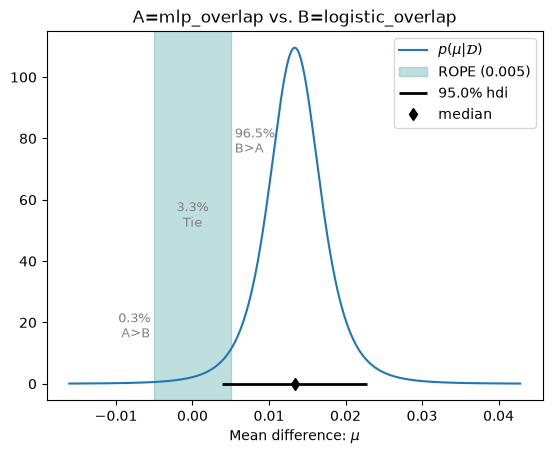

In [37]:
posterior.plot(rope_param=ROPE)
plt.show()


In [38]:
baseline_comparison = bayesian_compare(
    "majority", "logistic_overlap"
)[1]
baseline_comparison


model A                              majority
model B                      logistic_overlap
mean difference (B - A)              0.258795
P(A better)                               0.0
P(practically equivalent)                 0.0
P(B better)                               1.0
ROPE                                    0.005
dtype: object